# Sampler interface

This notebook provides the interface with `Cobaya` to run an MCMC parameter inference on the mock datasets generated with `horizon`.

## Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from chainconsumer import Chain, ChainConsumer, PlotConfig, Truth

from tools.utilities import Utilities

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

green        = ['#a6dba0','#5aae61','#1b7837']
purple       = ['#c2a5cf', '#9970ab', '#762a83']
analogous    = ['#a0c3db', '#dbb7a0']
warm         = ['#fdcc8a', '#fc8d59', '#d7301f']
cool         = ['#41b6c4', '#2c7fb8', '#253494']

### Detect settings from datafile

In [2]:
# find all datasets
datasets, unmatched = Utilities.list_mock_datasets()

# show them
Utilities.print_mock_datasets(datasets, unmatched)

[0] M1 α=-0.075 β=0.0 n_QSO=1000 errors=targeted
[1] M1 α=-0.075 β=0.0 n_QSO=50 errors=current
[2] M1 α=-0.075 β=0.0 n_QSO=100 errors=current
[3] M1 α=-0.075 β=0.0 n_QSO=200 errors=current
[4] M1 α=0.1 β=0.0 n_QSO=50 errors=current
[5] M1 α=0.1 β=0.0 n_QSO=50 errors=future
[6] M1 α=0.1 β=0.0 n_QSO=100 errors=current
[7] M1 α=0.1 β=0.0 n_QSO=200 errors=current
[8] M1 α=0.1 β=0.0 n_QSO=200 errors=unspecified
[9] M2 α=0.1 β=0.1 n_QSO=50 errors=current
[10] M2 α=0.1 β=0.1 n_QSO=100 errors=current


In [3]:
# select by index in the list above, returns a dictionary of that dataset's settings
dataset = Utilities.select_mock_dataset(index=3, datasets=datasets)

### Run Cobaya

In [4]:
from cobaya.run import run
from likelihood import DDRlike

# build the Cobaya info dict directly from the selected dataset
# priors and MCMC settings are fixed inside Utilities.sampler_config
# the sampled parameters follow the dataset's DDR model (M1/M3: alpha; M2: alpha, beta)

info = Utilities.sampler_config(dataset, DDRlike)
info['debug'] = False

# Run MCMC sampling
updated_info, sampler = run(info)

[output] Output to be read-from/written-into folder 'chains', with prefix 'M1alpha-0.075beta0.0nQSO200_current'
--- [DDRlike] Model Selected: M1 ---
[DDRlike] Loading data from: ./mock_data/M1alpha-0.075beta0.0nQSO200_current
[mcmc] Getting initial point... (this may take a few seconds)
[mcmc] Initial point: alpha:-0.04661647
[model] Measuring speeds... (this may take a few seconds)
[model] Setting measured speeds (per sec): {DDRlike: 78100.0}
[mcmc] Covariance matrix not present. We will start learning the covariance of the proposal earlier: R-1 = 30 (would be 2 if all params loaded).
[mcmc] Sampling!
[mcmc] Progress @ 2026-09-07 16:16:58 : 1 steps taken, and 0 accepted.
[mcmc] Learn + convergence test @ 40 samples accepted.
[mcmc]  - Acceptance rate: 0.421
[mcmc]  - Convergence of means: R-1 = 0.484356 after 32 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.
[mcmc] Learn + convergence test @ 80 samples accepted.
[mcmc]  - Acceptance rate: 0.386
[mcmc]  - Convergen

### Plot contours with chainconsumer

Available columns: ['weight', 'minuslogpost', 'alpha', 'minuslogprior', 'minuslogprior__0', 'chi2', 'chi2__DDRlike']
Chain shape: (160, 7)



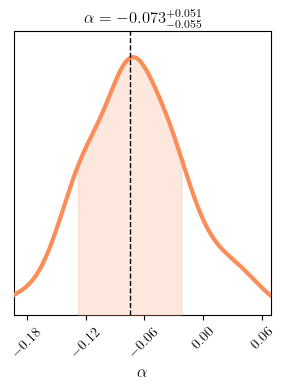

In [5]:
# Read the chain file from Cobaya output
chain_file = 'chains/'+dataset['settings']+'.1.txt'

# Read the header line to get column names
with open(chain_file, 'r') as f:
    header_line = f.readline()

# Extract column names from the header (remove # and split)
column_names = header_line.strip('#').split()

# Read the chain data with explicit column names
df = pd.read_csv(chain_file, sep=r'\s+', comment='#', names=column_names, header=None)

# Print available columns for debugging
print("Available columns:", df.columns.tolist())
print(f"Chain shape: {df.shape}")
print()

# Take the sampled parameters and their labels from the same config used to run,
# so this cell follows the dataset's model instead of assuming one
params = list(info['params'].keys())
labels = {p: '$' + Utilities.PARAM_TEMPLATE[p]['latex'] + '$' for p in params}
weights = df['weight'].values

# Create ChainConsumer object
c = ChainConsumer()

# Add the chain with proper column names and weights
c.add_chain(Chain(samples=df[params], weights=weights, name="DDR", 
                  bins=10, smooth=20,
                  shade_gradient=0.8, linewidth=3, color=warm[1]))

c.set_plot_config(PlotConfig(labels=labels, usetex=True, serif=True))

c.add_truth(Truth(location={"alpha": -0.075,}, color="k"))

# Generate triangle plot
fig = c.plotter.plot(figsize=(3,4))

# Adjust layout for better display
plt.tight_layout()
# plt.savefig('/home/nataliehogg/Documents/Projects/davide/figures/current_200.pdf')
plt.show()

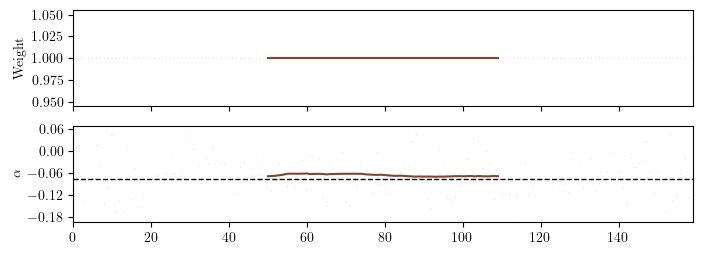

In [6]:
fig = c.plotter.plot_walks(convolve=100)